# 02 - Exploratory data analysis

**Goal:** test each branch of the driver tree in [`docs/01_problem_framing.md`](../docs/01_problem_framing.md) against the data, and update the status of each "why".

**Input:** `data/processed/transactions_clean.csv`

| Branch | Section |
|---|---|
| Revenue trend and seasonality | 2 |
| Customer base: new vs. existing | 3 |
| Customer concentration | 4 |
| Order value and frequency | 5 |
| Leakage: cancellations and guest orders | 6 |
| Geography | 7 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd().parent  # notebook runs from notebooks/
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150)

In [2]:
df = pd.read_csv(
    ROOT / "data" / "processed" / "transactions_clean.csv",
    parse_dates=["invoice_date", "invoice_month", "first_purchase_month"],
    dtype={"invoice": str, "stock_code": str, "customer_id": "Int64"},
)

# Net sales = sales minus cancellations. Gross = sales only.
sales = df[~df.is_cancellation]
cancels = df[df.is_cancellation]
tracked = sales[sales.has_customer]  # customer-level analysis only

print(f"{len(df):,} rows | {df.invoice_date.min():%Y-%m-%d} to {df.invoice_date.max():%Y-%m-%d}")
print(f"gross sales £{sales.line_total.sum():,.0f} | cancelled £{-cancels.line_total.sum():,.0f}")

1,027,016 rows | 2009-12-01 to 2011-12-09
gross sales £20,476,260 | cancelled £1,462,424


## 1. Calendar coverage

The data ends on 9 Dec 2011, so December 2011 is a partial month and the 2009 start is also partial (December only). Comparisons below exclude partial months where it matters.

In [3]:
months = (
    sales.groupby("invoice_month")
    .agg(gross_sales=("line_total", "sum"), invoices=("invoice", "nunique"), customers=("customer_id", "nunique"))
)
months["days_with_sales"] = sales.groupby("invoice_month").invoice_date.apply(lambda s: s.dt.normalize().nunique())
months.tail(4)

,gross_sales,invoices,customers,days_with_sales
invoice_month,,,,
2011-09-01,"1,056,435.19",1837,1266,26
2011-10-01,"1,151,263.73",2040,1364,26
2011-11-01,"1,503,866.78",2769,1664,26
2011-12-01,"637,808.33",819,615,8


## 2. Revenue trend and seasonality

*Driver tree: Order frequency → Seasonality (Q4 peak vs. rest of year).*

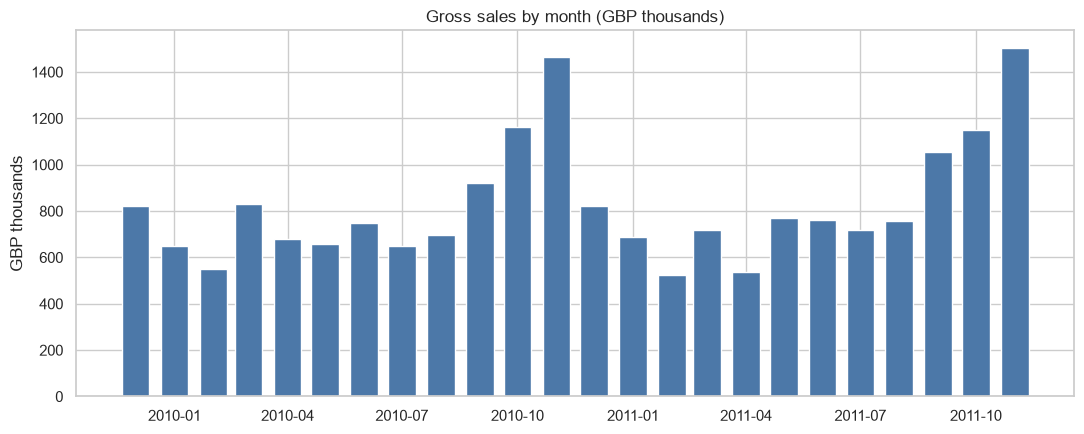

In [4]:
full_months = months.drop(months.index[-1])  # drop partial Dec 2011

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(full_months.index, full_months.gross_sales / 1e3, width=22, color="#4C78A8")
ax.set_title("Gross sales by month (GBP thousands)")
ax.set_ylabel("GBP thousands")
save(fig, "02_monthly_gross_sales")
plt.show()

In [5]:
# Year-over-year, like-for-like: Jan-Nov of 2010 vs 2011
yoy = (
    sales[sales.invoice_date.dt.month <= 11]
    .groupby(sales.invoice_date.dt.year).line_total.sum()
    .loc[[2010, 2011]]
)
print(yoy)
print(f"Jan-Nov 2011 vs Jan-Nov 2010: {yoy[2011] / yoy[2010] - 1:+.1%}")

invoice_date
2010   9,011,647.68
2011   9,182,867.74
Name: line_total, dtype: float64
Jan-Nov 2011 vs Jan-Nov 2010: +1.9%


In [6]:
# Share of annual sales earned in Sep-Nov (peak season), for the two full years
for year in (2010, 2011):
    y = sales[sales.invoice_date.dt.year == year]
    peak = y[y.invoice_date.dt.month.isin([9, 10, 11])].line_total.sum()
    print(f"{year}: Sep-Nov share of Jan-Nov sales = {peak / y[y.invoice_date.dt.month <= 11].line_total.sum():.1%}")

2010: Sep-Nov share of Jan-Nov sales = 39.4%


2011: Sep-Nov share of Jan-Nov sales = 40.4%


## 3. Customer base: new vs. returning

*Driver tree: Customer base → New customers / Existing customers.*

A customer is **new** in the month of their first purchase and **returning** afterwards. Only tracked (non-guest) customers can be classified.

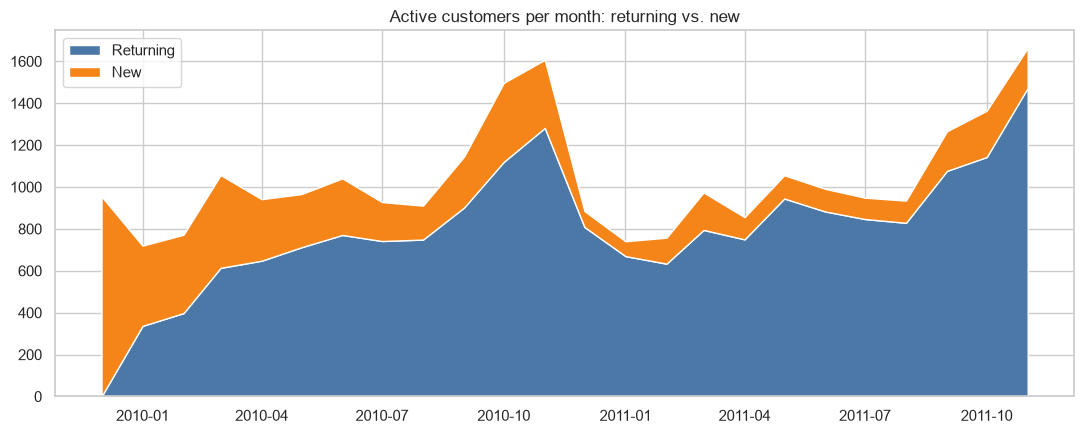

In [7]:
active = (
    tracked.assign(is_new=tracked.invoice_month == tracked.first_purchase_month)
    .groupby(["invoice_month", "is_new"]).customer_id.nunique()
    .unstack(fill_value=0)
    .rename(columns={True: "new", False: "returning"})
)
active = active.drop(active.index[-1])  # partial month

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(active.index, active["returning"], active["new"], labels=["Returning", "New"], colors=["#4C78A8", "#F58518"])
ax.set_title("Active customers per month: returning vs. new")
ax.legend(loc="upper left")
save(fig, "02_new_vs_returning_customers")
plt.show()

In [8]:
# Revenue from returning vs new customers (full months only)
rev = (
    tracked[tracked.invoice_month < tracked.invoice_month.max()]
    .assign(kind=lambda d: np.where(d.invoice_month == d.first_purchase_month, "new", "returning"))
    .groupby("kind").line_total.sum()
)
(rev / rev.sum()).to_frame("share_of_tracked_sales")

,share_of_tracked_sales
kind,
new,0.18
returning,0.82


In [9]:
# Like-for-like (Jan-Nov) comparison: did growth come from new or existing customers?
# Caveat: the data starts in Dec 2009, so "new in 2010" can include customers who bought before the window.
jan_nov = tracked[tracked.invoice_date.dt.month <= 11].assign(
    year=lambda d: d.invoice_date.dt.year,
    kind=lambda d: np.where(d.invoice_month == d.first_purchase_month, "new", "returning"),
)
jan_nov = jan_nov[jan_nov.year.isin([2010, 2011])]
by_kind = jan_nov.groupby(["year", "kind"]).agg(sales=("line_total", "sum"), customers=("customer_id", "nunique")).unstack()
by_kind

sales              customers          
kind          new    returning       new returning
year                                              
2010 1,563,802.89 6,240,270.46      3311      2646
2011   724,074.57 7,075,521.15      1508      3357

In [10]:
# Left-censoring check: early-2010 "new" customers may have bought before Dec 2009.
# Jun-Nov is far enough from the start of the data to be less affected.
first_seen = tracked.drop_duplicates("customer_id")[["customer_id", "first_purchase_month"]]
for first_month in (1, 6):
    in_window = first_seen[first_seen.first_purchase_month.dt.month.between(first_month, 11)]
    n = in_window.groupby(in_window.first_purchase_month.dt.year).size().loc[[2010, 2011]]
    print(f"new customers, months {first_month}-11: 2010 = {n[2010]:,}, 2011 = {n[2011]:,} ({n[2011] / n[2010] - 1:+.0%})")

new customers, months 1-11: 2010 = 3,311, 2011 = 1,508 (-54%)
new customers, months 6-11: 2010 = 1,563, 2011 = 917 (-41%)


In [11]:
# Repeat purchase rate: customers with 2+ distinct invoices
inv_per_customer = tracked.groupby("customer_id").invoice.nunique()
print(f"customers: {len(inv_per_customer):,}")
print(f"repeat purchase rate (2+ invoices): {(inv_per_customer >= 2).mean():.1%}")
inv_per_customer.describe().to_frame("invoices_per_customer")

customers: 5,878
repeat purchase rate (2+ invoices): 72.4%


,invoices_per_customer
count,"5,878.00"
mean,6.29
std,13.01
min,1.00
25%,1.00
50%,3.00
75%,7.00
max,398.00


## 4. Customer concentration

*Driver tree: Existing customers → Concentration risk.*

top   1% of customers (58) = 31.8% of tracked sales
top   5% of customers (293) = 51.9% of tracked sales
top  10% of customers (587) = 63.9% of tracked sales
top  20% of customers (1,175) = 77.2% of tracked sales


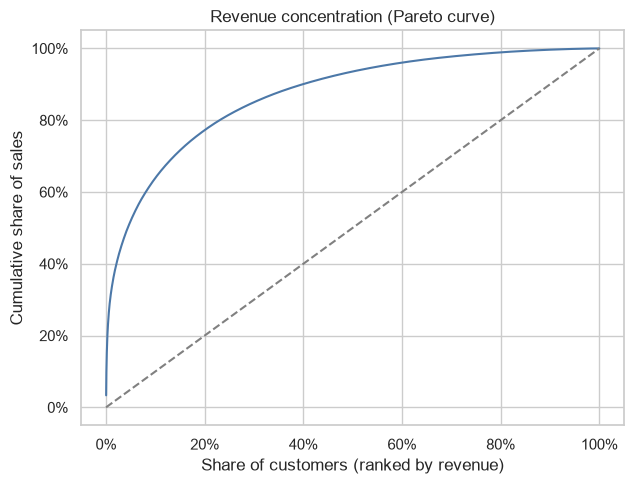

In [12]:
cust_rev = tracked.groupby("customer_id").line_total.sum().sort_values(ascending=False)
cum_share = cust_rev.cumsum() / cust_rev.sum()
x = np.arange(1, len(cust_rev) + 1) / len(cust_rev)

for pct in (0.01, 0.05, 0.10, 0.20):
    n = int(len(cust_rev) * pct)
    print(f"top {pct:>4.0%} of customers ({n:,}) = {cum_share.iloc[n - 1]:.1%} of tracked sales")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(x, cum_share.values, color="#4C78A8")
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_xlabel("Share of customers (ranked by revenue)")
ax.set_ylabel("Cumulative share of sales")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Revenue concentration (Pareto curve)")
save(fig, "02_customer_concentration")
plt.show()

In [13]:
# Are the biggest customers wholesalers? Look at the top 10.
top10 = (
    tracked.groupby("customer_id")
    .agg(sales=("line_total", "sum"), invoices=("invoice", "nunique"), country=("country", "first"))
    .sort_values("sales", ascending=False)
    .head(10)
)
top10

,sales,invoices,country
customer_id,,,
18102,"580,987.04",145,United Kingdom
14646,"528,602.52",151,Netherlands
14156,"313,437.62",156,EIRE
14911,"291,420.81",398,EIRE
17450,"244,784.25",51,United Kingdom
13694,"195,640.69",143,United Kingdom
17511,"172,132.87",60,United Kingdom
16446,"168,472.50",2,United Kingdom
16684,"147,142.77",55,United Kingdom


## 5. Order value and frequency

*Driver tree: Order value → Basket size, unit price. Order frequency → Inter-purchase time.*

In [14]:
invoices = (
    sales.groupby("invoice")
    .agg(month=("invoice_month", "first"), value=("line_total", "sum"), lines=("stock_code", "count"), units=("quantity", "sum"))
)
print(invoices[["value", "lines", "units"]].describe().round(1))

           value     lines     units
count  40,077.00 40,077.00 40,077.00
mean      510.90     25.10    279.60
std     1,482.30     42.50  1,196.20
min         0.20      1.00      1.00
25%       149.80      6.00     64.00
50%       302.20     15.00    146.00
75%       493.40     29.00    288.00
max   168,469.60  1,114.00 87,167.00


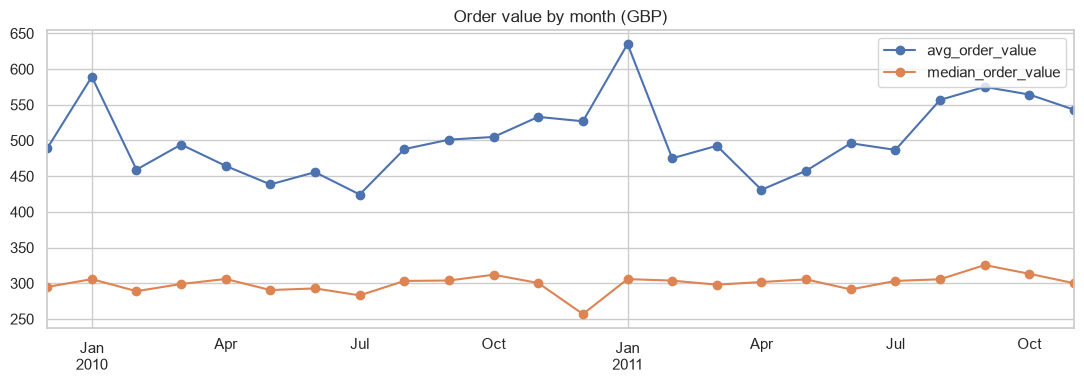

In [15]:
aov = invoices.groupby("month").agg(avg_order_value=("value", "mean"), median_order_value=("value", "median"))
aov = aov.drop(aov.index[-1])

fig, ax = plt.subplots(figsize=(11, 4))
aov.plot(ax=ax, marker="o")
ax.set_title("Order value by month (GBP)")
ax.set_xlabel("")
save(fig, "02_order_value")
plt.show()

       gap_days
count 26,838.00
mean      59.90
std       78.50
min        1.00
25%       13.20
50%       32.00
75%       71.10
max      714.20


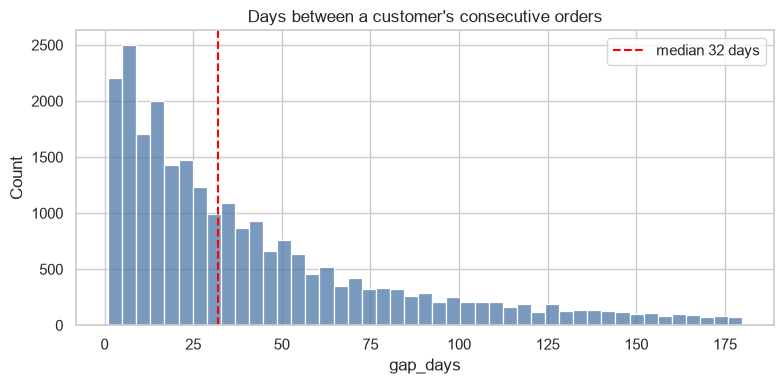

In [16]:
# Inter-purchase time: days between a tracked customer's consecutive invoices
orders = (
    tracked.groupby(["customer_id", "invoice"]).invoice_date.min().reset_index()
    .sort_values(["customer_id", "invoice_date"])
)
orders["gap_days"] = orders.groupby("customer_id").invoice_date.diff().dt.total_seconds() / 86400
gaps = orders.gap_days.dropna()
gaps = gaps[gaps >= 1]  # same-day extra invoices are not a "return"

print(gaps.describe().round(1).to_frame("gap_days"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(gaps[gaps <= 180], bins=45, ax=ax, color="#4C78A8")
ax.axvline(gaps.median(), color="red", ls="--", label=f"median {gaps.median():.0f} days")
ax.set_title("Days between a customer's consecutive orders")
ax.legend()
save(fig, "02_inter_purchase_gap")
plt.show()

## 6. Leakage: cancellations and guest orders

*Driver tree: Leakage → Cancellations, Returns, Guest orders with no customer ID.*

overall cancelled value / gross sales: 7.1%
cancellation invoices / all invoices: 17.1%


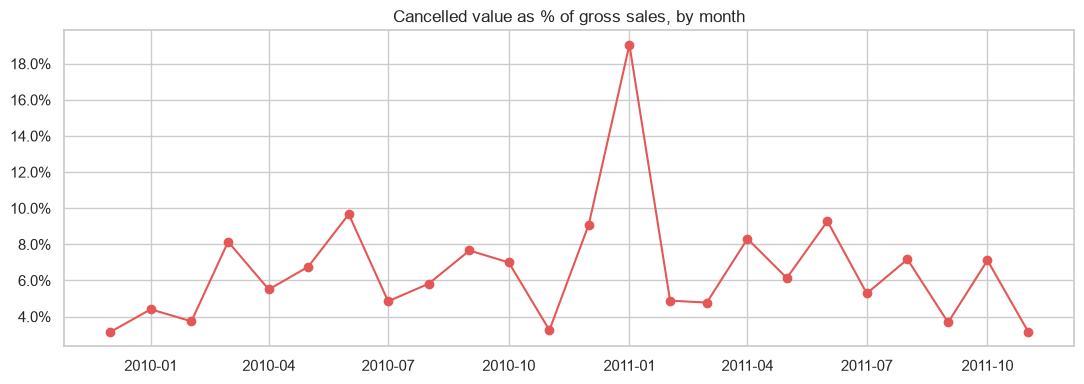

In [17]:
monthly_cancel = pd.DataFrame({
    "gross_sales": sales.groupby("invoice_month").line_total.sum(),
    "cancelled": -cancels.groupby("invoice_month").line_total.sum(),
}).iloc[:-1]
monthly_cancel["cancel_rate"] = monthly_cancel.cancelled / monthly_cancel.gross_sales

print(f"overall cancelled value / gross sales: {-cancels.line_total.sum() / sales.line_total.sum():.1%}")
print(f"cancellation invoices / all invoices: {cancels.invoice.nunique() / df.invoice.nunique():.1%}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly_cancel.index, monthly_cancel.cancel_rate, marker="o", color="#E45756")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Cancelled value as % of gross sales, by month")
save(fig, "02_cancellation_rate")
plt.show()

### 6.1 Entry-error reversals

Two customers (16446 and 12346) have a huge sale cancelled minutes later for the same product and quantity (80,995 and 74,215 units). These look like data-entry errors, not real demand or real churn. Find every sale that was fully reversed within an hour, and measure how much they distort gross sales and the cancellation rate.

In [18]:
key = ["customer_id", "stock_code", "quantity"]
sale_lines = sales[sales.has_customer][key + ["invoice", "invoice_date", "line_total"]]
cancel_lines = cancels[cancels.has_customer].assign(quantity=lambda d: -d.quantity)[key + ["invoice", "invoice_date"]]

pairs = cancel_lines.merge(sale_lines, on=key, suffixes=("_cancel", "_sale"))
lag = pairs.invoice_date_cancel - pairs.invoice_date_sale
pairs = pairs[(lag >= pd.Timedelta(0)) & (lag <= pd.Timedelta("1h"))]
pairs = pairs.drop_duplicates(key + ["invoice_cancel"])

reversed_value = pairs.line_total.sum()
print(f"sale lines reversed within 1 hour: {len(pairs):,} worth £{reversed_value:,.0f}")
print(f"  = {reversed_value / -cancels.line_total.sum():.1%} of all cancelled value, {reversed_value / sales.line_total.sum():.1%} of gross sales")
print(f"cancellation rate excl. these: {(-cancels.line_total.sum() - reversed_value) / (sales.line_total.sum() - reversed_value):.1%}")
pairs.nlargest(5, "line_total")[["customer_id", "stock_code", "quantity", "line_total"]]

sale lines reversed within 1 hour: 1,078 worth £379,835
  = 26.0% of all cancelled value, 1.9% of gross sales
cancellation rate excl. these: 5.4%


,customer_id,stock_code,quantity,line_total
15177,16446,23843,80995,"168,469.60"
8287,12346,23166,74215,"77,183.60"
1910,12918,M,1,"10,953.50"
1069,17949,M,1,"8,985.60"
1863,15760,M,1,"6,958.17"


In [19]:
# Concentration check: drop the reversed lines and recompute the top-customer share
reversed_invoices = pairs[["customer_id", "invoice_sale"]].drop_duplicates()
clean_tracked = tracked.merge(
    reversed_invoices.rename(columns={"invoice_sale": "invoice"}).assign(reversed=True),
    on=["customer_id", "invoice"], how="left",
)
clean_tracked = clean_tracked[clean_tracked.reversed.isna()]

cust_rev_adj = clean_tracked.groupby("customer_id").line_total.sum().sort_values(ascending=False)
cum_adj = cust_rev_adj.cumsum() / cust_rev_adj.sum()
for pct in (0.01, 0.05, 0.10, 0.20):
    print(f"top {pct:>4.0%} of customers = {cum_adj.iloc[int(len(cust_rev_adj) * pct) - 1]:.1%} of tracked sales (excl. reversals)")

top   1% of customers = 31.1% of tracked sales (excl. reversals)
top   5% of customers = 51.3% of tracked sales (excl. reversals)
top  10% of customers = 63.3% of tracked sales (excl. reversals)
top  20% of customers = 76.9% of tracked sales (excl. reversals)


In [20]:
# Are cancellations concentrated in a few customers?
cancel_by_cust = (-cancels[cancels.has_customer].groupby("customer_id").line_total.sum()).sort_values(ascending=False)
print(f"customers with any cancellation: {len(cancel_by_cust):,} of {tracked.customer_id.nunique():,}")
print(f"top 10 customers = {cancel_by_cust.head(10).sum() / cancel_by_cust.sum():.1%} of tracked cancelled value")
print(f"cancelled value with no customer ID: £{-cancels.loc[~cancels.has_customer, 'line_total'].sum():,.0f}")
cancel_by_cust.head(5).to_frame("cancelled_gbp")

customers with any cancellation: 2,572 of 5,878
top 10 customers = 42.1% of tracked cancelled value
cancelled value with no customer ID: £377,611


,cancelled_gbp
customer_id,
16446,"168,478.60"
12346,"77,608.20"
15098,"39,267.00"
16029,"28,058.15"
14063,"26,477.40"


guest share of gross sales: 15.1%


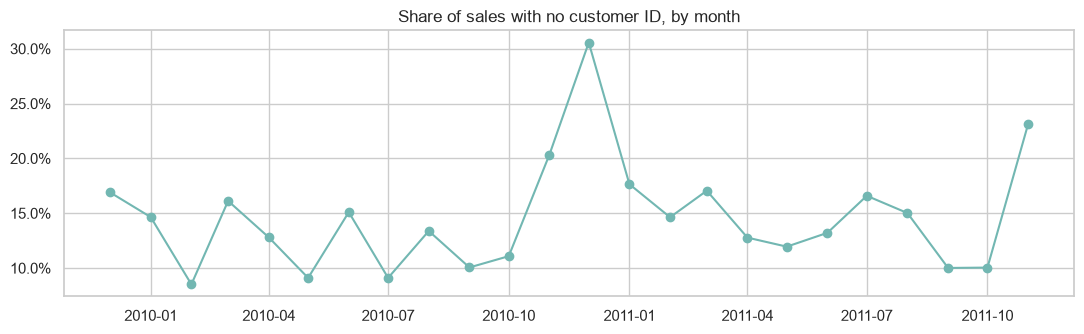

In [21]:
# Guest (no customer ID) share of sales over time
guest = sales.groupby(["invoice_month", "has_customer"]).line_total.sum().unstack()
guest_share = (guest[False] / guest.sum(axis=1)).iloc[:-1]

print(f"guest share of gross sales: {sales.loc[~sales.has_customer, 'line_total'].sum() / sales.line_total.sum():.1%}")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(guest_share.index, guest_share.values, marker="o", color="#72B7B2")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Share of sales with no customer ID, by month")
save(fig, "02_guest_share")
plt.show()

## 7. Geography

In [22]:
country = (
    sales.groupby("country")
    .agg(sales=("line_total", "sum"), customers=("customer_id", "nunique"))
    .sort_values("sales", ascending=False)
)
country["share"] = country.sales / country.sales.sum()
country.head(8)

,sales,customers,share
country,,,
United Kingdom,"17,410,196.10",5350,0.85
EIRE,"658,767.31",5,0.03
Netherlands,"554,038.09",22,0.03
Germany,"425,019.71",107,0.02
France,"350,456.09",95,0.02
Australia,"169,283.46",15,0.01
Spain,"108,332.49",41,0.01
Switzerland,"100,685.59",22,0.00


UK share of sales: 85.0% | non-UK countries: 42


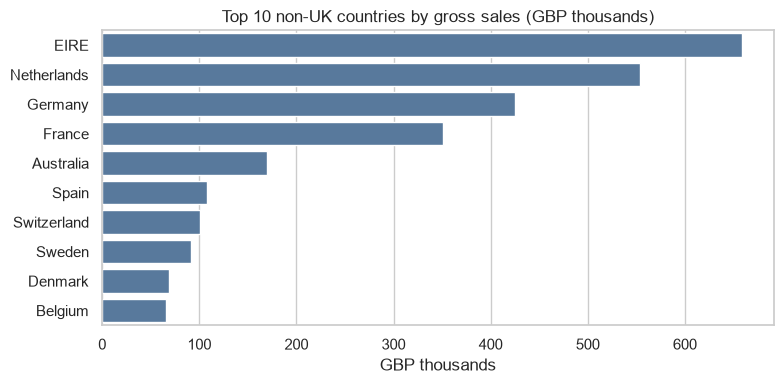

In [23]:
uk_share = country.loc["United Kingdom", "share"]
print(f"UK share of sales: {uk_share:.1%} | non-UK countries: {len(country) - 1}")
non_uk = country.drop("United Kingdom").head(10)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=non_uk.sales / 1e3, y=non_uk.index, ax=ax, color="#4C78A8")
ax.set_title("Top 10 non-UK countries by gross sales (GBP thousands)")
ax.set_xlabel("GBP thousands")
ax.set_ylabel("")
save(fig, "02_top_countries")
plt.show()

## 8. Key takeaways

**Headline:** the first hypothesis was wrong. The business is not losing customers after one purchase (72% place 2+ orders). The stall is in **new-customer acquisition**, and growth depends on a **concentrated base of repeat wholesale buyers**.

| Finding | Evidence |
|---|---|
| Sales are flat | Jan-Nov 2011 vs Jan-Nov 2010: **+1.9%** |
| Growth came from existing customers, not new ones | Jan-Nov new-customer sales fell from £1.56M to £0.72M (3,311 to 1,508 new customers, -54%; -41% for Jun-Nov, which is less affected by the data starting in Dec 2009), returning-customer sales rose from £6.24M to £7.08M |
| Strong repeat behaviour | **72.4%** of tracked customers placed 2+ orders; 82% of tracked sales come from returning customers |
| Strong seasonality | Sep-Nov is ~40% of Jan-Nov sales in both years |
| Typical re-order rhythm | Median gap between orders is **32 days**; 75% of gaps are under 71 days |
| High concentration | Top 1% of customers = 31% of tracked sales, top 10% = 63%, top 20% = 77% |
| Cancellations | **7.1%** of gross sales (17% of invoices). 26% of cancelled value was reversed within an hour, which looks like entry corrections. Excluding those, the rate is 5.4% |
| Guest orders | **15%** of gross sales have no customer ID, so they cannot be tracked or retained |
| Geography | UK is 85% of sales; EIRE, Netherlands, Germany and France follow |

### Data caveats
- Customers 16446 and 12346 each have one sale of 80k / 74k units cancelled within minutes. They inflate gross sales, cancellations and the top-customer ranking, so treat them as entry errors.
- The dataset starts in Dec 2009, so "new in 2010" may include customers who bought earlier.
- Dec 2011 is a partial month (to 9 Dec) and is excluded from monthly trends.

### 5 Whys status after EDA

| # | Hypothesis | Status |
|---|---|---|
| 1 | Too few customers keep buying after their first orders | **Refuted.** Repeat rate is 72%. Revised: growth is flat while new-customer acquisition fell 40-55% (retention did not get worse) |
| 2 | Revenue depends on a small set of customers | **Confirmed** (top 10% = 63% of sales). Churn of that group still to test |
| 3 | Purchase gaps lengthen before churn | To test (notebook 03/05) |
| 4 | Seasonal mix and cancellations drive gaps | **Partly.** Seasonality confirmed; cancellations are 5-7% of sales. Product mix: small effect, tested in notebook 11 |
| 5 | No early-warning signal | To test (notebook 05) |

### Next questions
1. Retention by cohort: do the larger 2010 cohorts decay faster than 2009's?
2. Why did new-customer acquisition fall in 2011?
3. Which high-value customers have gone quiet, using the 32-day median and ~71-day upper gap as a guide?